# The Boston housing  Price prediction

In [6]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


In [7]:
housing_data=pd.read_csv('datasets\HousingData.csv')

In [8]:
housing_data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [9]:
housing_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [10]:
housing_data.isnull().sum()


CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
MEDV        0
dtype: int64

c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

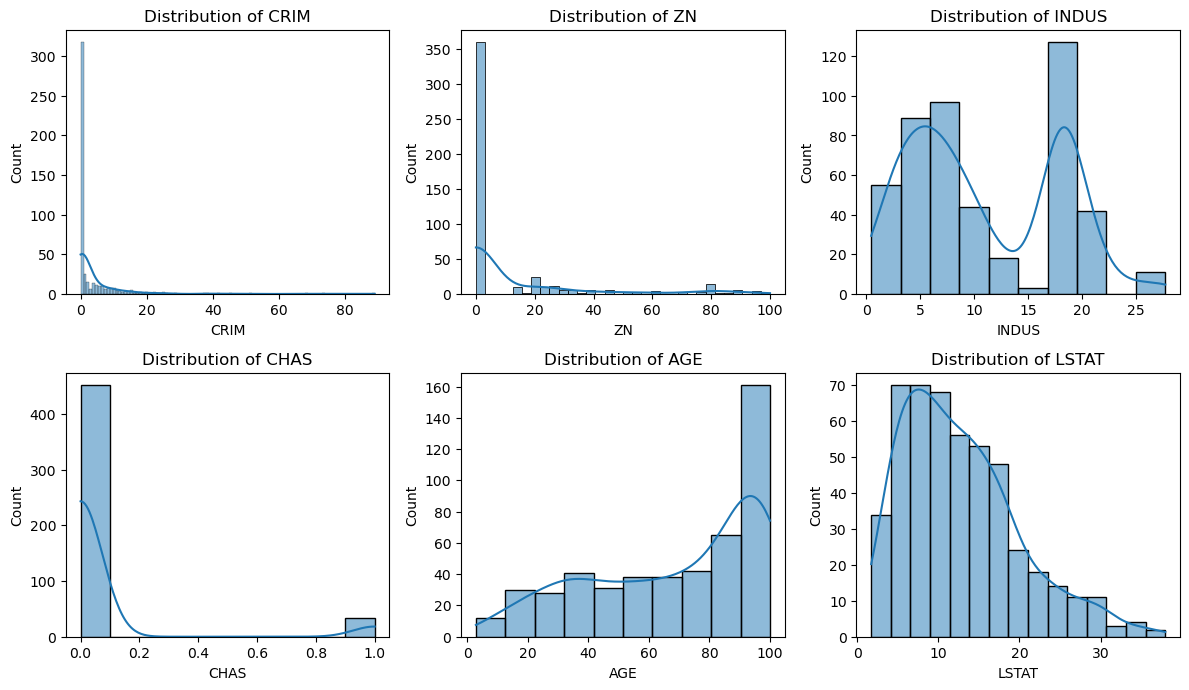

In [11]:
col_missing = ['CRIM','ZN','INDUS','CHAS','AGE','LSTAT']
plt.figure(figsize=(12,10))
for i,col in enumerate(col_missing,1):
    plt.subplot(3,3,i)
    sns.histplot(housing_data[col],kde=True)
    plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

In [12]:
housing_data["CRIM"]= housing_data["CRIM"].fillna(housing_data['CRIM'].median())
housing_data['ZN']=housing_data['ZN'].fillna(housing_data['ZN'].median())
housing_data['INDUS']=housing_data['INDUS'].fillna(housing_data['INDUS'].median())
housing_data['CHAS'] = housing_data['CHAS'].fillna(housing_data['CHAS'].median())
housing_data['AGE']= housing_data['AGE'].fillna(housing_data['AGE'].median())
housing_data['LSTAT']= housing_data['LSTAT'].fillna(housing_data['LSTAT'].mean())

In [13]:
housing_data.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

In [14]:
x=housing_data.drop(columns=["MEDV"],axis=1)
y=housing_data["MEDV"]

In [15]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.30,random_state=42)

In [16]:
print(x_train.shape,x_test.shape)

(354, 13) (152, 13)


In [17]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()


In [18]:
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [19]:
# to inverse the x_train 
#scaler.inverse_transform(x_train)

In [20]:
regression = LinearRegression()
regression.fit(x_train,y_train)

LinearRegression()

In [21]:

from sklearn.model_selection import cross_val_score
mse=cross_val_score(regression,x_train,y_train,scoring='neg_mean_squared_error',cv=5)


In [22]:
np.mean(mse)

-27.159322670173975

In [23]:
pred=regression.predict(x_test)

c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


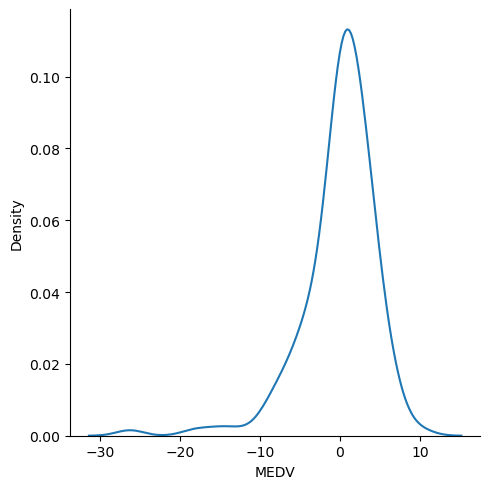

In [24]:
sns.displot(pred-y_test,kind='kde')

In [25]:
from sklearn.metrics import r2_score
score=r2_score(pred,y_test)
score

0.6641694423507083

# Ridge Regression
1. Used to handle overfiting conditon

In [26]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

In [27]:
ridge_regression = Ridge()

In [28]:
paramas = {'alpha':[1,2,5,10,30,40,50,60]}
ridgecv = GridSearchCV(ridge_regression,paramas,scoring='neg_mean_squared_error',cv=5)
ridgecv.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [1, 2, 5, 10, 30, 40, 50, 60]},
             scoring='neg_mean_squared_error')

In [30]:
print(ridgecv.best_params_)
print(ridgecv.best_score_)

{'alpha': 10}
-26.910511423545017


In [31]:
ridge_pred=ridgecv.predict(x_test)

c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


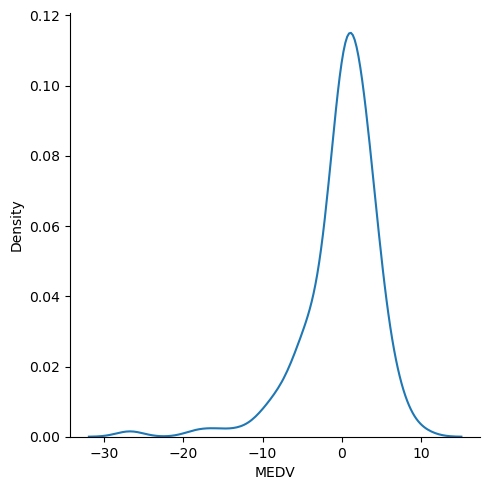

In [32]:
sns.displot(ridge_pred-y_test,kind='kde')